# **Programme Performance and Audience Engagement Analysis**

## **Part 1 - Data Cleaning and Preparation**

This section combines March, April, and May 2025 viewing records into a consistent dataset for programme-level and time-based analysis.

The data preparation process includes:
- Combining monthly datasets into one table.
- Standardising programme titles using a master lookup table.
- Extracting programme titles from content names when lookup matches are unavailable.
- Retaining the fields required for viewership analysis.

In [ ]:
import pandas as pd
import numpy as np
import re

In [ ]:
# Load the Excel file
xls = pd.ExcelFile("/content/data-analyst-task.xlsx")

# Load all sheets
march = xls.parse('March')
april = xls.parse('April')
may = xls.parse('May')
lookup = xls.parse('MASTER_LOOKUP')

In [ ]:
# Combining the three months into one table
df = pd.concat([march, april, may], ignore_index=True)

# Converting the date column into actual date format
df['Event Start Date'] = pd.to_datetime(df['Event Start Date'])

# Content Code is treated like a string (not a number)
df['Content Code'] = df['Content Code'].astype(str)

In [ ]:
print("🧾 Combined Raw Dataset (First 10 Rows)")
display(df[['Event Start Date', 'Views', 'Content Publisher', 'Content Name', 'Content Code']].head(10))

🧾 Combined Raw Dataset (First 10 Rows)


,Event Start Date,Views,Content Publisher,Content Name,Content Code
0,2025-03-01,5,Crime,#Dead2Me (s1): ep 01 (HD),900000002510214
1,2025-03-02,14,Crime,#Dead2Me (s1): ep 01 (HD),900000002510214
2,2025-03-03,3,Crime,#Dead2Me (s1): ep 01 (HD),900000002510214
3,2025-03-04,5,Crime,#Dead2Me (s1): ep 01 (HD),900000002510214
4,2025-03-06,3,Crime,#Dead2Me (s1): ep 01 (HD),900000002510214
5,2025-03-08,5,Crime,#Dead2Me (s1): ep 01 (HD),900000002510214
6,2025-03-09,3,Crime,#Dead2Me (s1): ep 01 (HD),900000002510214
7,2025-03-11,3,Crime,#Dead2Me (s1): ep 01 (HD),900000002510214
8,2025-03-12,5,Crime,#Dead2Me (s1): ep 01 (HD),900000002510214
9,2025-03-14,5,Crime,#Dead2Me (s1): ep 01 (HD),900000002510214


The table above displays the first 10 rows of the combined dataset before programme-title standardisation. It includes event dates, view counts, publisher names, content names, and content codes.

Content names may contain additional metadata, such as season or episode information, which can create inconsistencies when aggregating views by programme. The next steps standardise programme titles to support consistent analysis.

In [ ]:
# Change PROGRAMME_ID to string, so it matches Content Code
lookup['PROGRAMME_ID'] = lookup['PROGRAMME_ID'].astype('Int64').astype(str)

# Keep only the useful columns
lookup_clean = lookup[['PROGRAMME_ID', 'PROGRAMME_TITLE']]

In [ ]:
# Add clean programme titles from the lookup table
df = df.merge(lookup_clean, how='left', left_on='Content Code', right_on='PROGRAMME_ID')

In [ ]:
# If PROGRAMME_TITLE is missing, extract from 'Content Name'
def extract_title(content):
    if pd.isna(content): return None
    match = re.match(r"(#?\w[\w\s&\-]*)", content)
    return match.group(1).strip() if match else content.strip()

# Fill in missing programme titles by extracting from 'Content Name'
df['PROGRAMME_TITLE'] = df['PROGRAMME_TITLE'].fillna(df['Content Name'].apply(extract_title))

In [ ]:
# Keep only the important columns
clean_df = df[['Event Start Date', 'Views', 'Content Publisher', 'PROGRAMME_TITLE']]

# Rename the columns for clarity
clean_df.columns = ['Date', 'Views', 'Publisher', 'Programme']

# Show first 10 rows
clean_df.head(10)

,Date,Views,Publisher,Programme
0,2025-03-01,5,Crime,#Dead2Me
1,2025-03-02,14,Crime,#Dead2Me
2,2025-03-03,3,Crime,#Dead2Me
3,2025-03-04,5,Crime,#Dead2Me
4,2025-03-06,3,Crime,#Dead2Me
5,2025-03-08,5,Crime,#Dead2Me
6,2025-03-09,3,Crime,#Dead2Me
7,2025-03-11,3,Crime,#Dead2Me
8,2025-03-12,5,Crime,#Dead2Me
9,2025-03-14,5,Crime,#Dead2Me


The table above previews the cleaned dataset after programme-title standardisation. Programme titles are matched using the master lookup table, with text extraction applied where lookup matches are unavailable.

The final dataset retains four fields: date, views, publisher, and programme. This structure supports aggregation of viewership by programme and analysis of trends over time.

## **Part 2 - Viewership Analysis**

This section explores programme performance and audience viewing patterns across March, April, and May 2025.

The analysis focuses on:
- Ranking programmes by total views.
- Comparing monthly viewership totals.
- Visualising daily viewing patterns over the reporting period.

In [ ]:
# Group by Programme and sum the Views
top_programmes = clean_df.groupby('Programme')['Views'].sum().sort_values(ascending=False)

# Show Top 10 Programmes
print("Top 10 Most Watched Programmes (Total Views):")
display(top_programmes.head(10))

🏆 Top 10 Most Watched Programmes (Total Views):


,Views
Programme,
Bradley Walsh,238138
Gypsy Rose,215645
Ancient Aliens,184444
Ramses,111065
The Curse of Oak Island,88343
Cops Gone Bad with Will Mellor,78319
Homicide Hunter,76268
Pawn Stars,75526
Storage Wars,66853


### **Top-Performing Programmes**

Bradley Walsh recorded the highest total viewership, with 238,138 views. Other leading programmes included Gypsy Rose, Ancient Aliens, and Ramses.

The results show that viewership was concentrated among a small group of high-performing programme titles during the reporting period.

In [ ]:
# Create a new column for Month-Year
clean_df['Month'] = clean_df['Date'].dt.to_period('M')

# Group by Month and sum Views
monthly_views = clean_df.groupby('Month')['Views'].sum()

print("📅 Total Views by Month:")
display(monthly_views)

📅 Total Views by Month:


/tmp/ipython-input-3472672443.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  clean_df['Month'] = clean_df['Date'].dt.to_period('M')


,Views
Month,
2025-03,1553854
2025-04,1146918
2025-05,1140700


### **Monthly Viewership Trends**

- **March 2025:** 1,553,854 views.
- **April 2025:** 1,146,918 views.
- **May 2025:** 1,140,700 views.

March recorded the highest total viewership. Monthly totals were lower in April and May, with May remaining relatively close to April.

/tmp/ipython-input-204753984.py:11: UserWarning: Glyph 128200 (\N{CHART WITH UPWARDS TREND}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128200 (\N{CHART WITH UPWARDS TREND}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


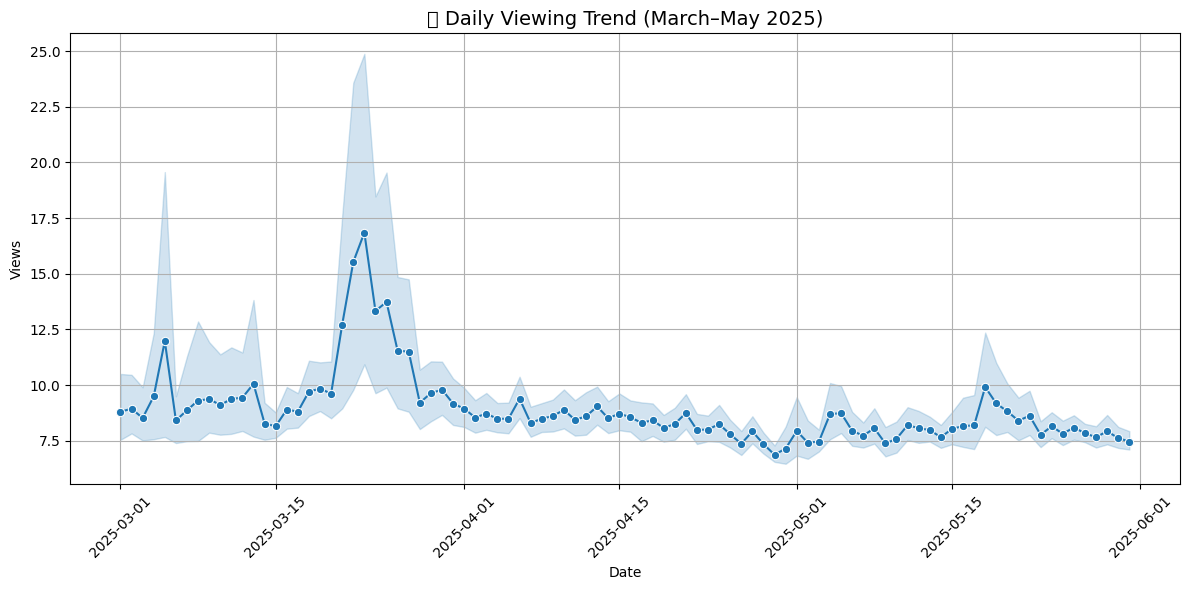

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))
sns.lineplot(data=clean_df, x='Date', y='Views', marker='o')
plt.title("📈 Daily Viewing Trend (March–May 2025)", fontsize=14)
plt.xlabel("Date")
plt.ylabel("Views")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

### **Daily Viewership Patterns**

The time-series visualisation shows daily viewership fluctuations across the three-month period.

- Viewership peaked during March, particularly around the middle of the month.
- Daily viewership was generally lower during April and May compared with the largest March peaks.
- Smaller fluctuations continued throughout the reporting period.

The chart highlights when viewing activity was higher or lower, although the underlying reasons for these changes cannot be established from view counts alone.

## **Part 3 - Final Summary and Strategic Insights**

This section provides summary of my findings, strategic insights and strategic recommendations for improvement.

### **Executive Summary**

This analysis examines programme performance and audience viewing patterns from March to May 2025.

The data preparation stage combined monthly records and standardised programme titles using a master lookup table and text extraction for unmatched entries. The cleaned data was then used to compare programme-level view counts, monthly totals, and daily viewing patterns.

The analysis identified the highest-performing programme titles, differences in monthly viewership, and periods of elevated daily activity. These findings provide a descriptive overview of viewing patterns during the reporting period.

### **Key Insights:**

 * **Bradley Walsh was the most-watched programme, attracting over 238,000**

This title significantly outperformed other programmes in terms of total views, indicating a strong and sustained level of interest from the audience. Its popularity may be attributed to brand recognition, engaging content, or loyal viewership, making it a clear candidate for continued investment or spin-off programming.

*   **March 2025 recorded the highest viewership (1.55M+), with a noticeable decline in April and May (~1.14M each)**

This month saw considerably more engagement than April and May (both ~1.14 million), suggesting a potential release of popular content, a successful marketing campaign, or naturally higher seasonal traffic during that period. The sharp contrast indicates a possible content lifecycle effect or a loss in user engagement if major titles concluded in March.

*   **The daily viewing trend showed consistent engagement with small peaks, especially mid-March, likely tied to popular content drops.**

Daily time-series analysis revealed a generally stable viewership pattern with regular fluctuations. Peaks in mid-March may correspond to major content drops or season finales, while the gradual tapering suggests the absence of similarly compelling releases in subsequent months. This pattern supports the importance of strategic content scheduling to sustain momentum.

*  **A small number of programmes dominated viewership, indicating high audience concentration around key titles.**

The distribution of viewership is heavily skewed toward a handful of top-performing titles. This concentration suggests that platform success is strongly driven by a limited catalogue of hit shows, rather than broad engagement across all content. Identifying and nurturing such high-performing content is critical for long-term retention and growth.



### **Strategic Recommendations**

- **Review high-performing programmes:** Use programme-level viewership rankings to identify titles that may merit further performance analysis.
- **Monitor monthly trends:** Continue tracking monthly viewership to determine whether the differences observed during this period persist.
- **Investigate daily peaks:** Compare periods of elevated viewing activity with available scheduling and release information to explore possible contributing factors.
- **Track programme-level performance over time:** Monitor whether leading titles maintain their viewership across subsequent reporting periods.